Connected to Python 3.13.2

In [ ]:
import numpy as np

class NN():
    def __init__(self, input_size, hidden_size, output_size, seed=None):
        self.input_size = input_size
        self.hidden_size = hidden_size
        self.output_size = output_size
        if seed is not None:
            np.random.seed(seed)
        # Xavier for sigmoid
        self.weights_input_hidden = np.random.randn(self.input_size, self.hidden_size) * np.sqrt(1.0/self.input_size)
        self.weights_hidden_output = np.random.randn(self.hidden_size, self.output_size) * np.sqrt(1.0/self.hidden_size)
        self.bias_hidden  = np.zeros((1, self.hidden_size))
        self.bias_output  = np.zeros((1, self.output_size))
        self.output_activation_type = None
        self.history_ = []

    def sigmoid(self, x):
        return 1/(1+np.exp(-x))
    def sigmoid_derivative_from_output(self, yhat):
        # yhat = sigmoid(z) -> derivative = yhat*(1-yhat)
        return yhat * (1 - yhat)

    def feedforward(self, X, output_activation='sigmoid'):
        self.output_activation_type = output_activation
        self.hidden_lin  = X @ self.weights_input_hidden + self.bias_hidden
        self.hidden_out  = self.sigmoid(self.hidden_lin)
        self.output_lin  = self.hidden_out @ self.weights_hidden_output + self.bias_output
        if output_activation == 'sigmoid':
            self.yhat = self.sigmoid(self.output_lin)
        elif output_activation == 'linear':
            self.yhat = self.output_lin
        else:
            raise ValueError("output_activation must be 'sigmoid' or 'linear'")
        return self.yhat

    def _loss(self, y, yhat, loss_type):
        if loss_type == 'mse':
            return np.mean((y - yhat)**2)
        elif loss_type == 'bce':
            # clip for numerical stability
            eps = 1e-12
            yhatc = np.clip(yhat, eps, 1 - eps)
            return -np.mean(y*np.log(yhatc) + (1-y)*np.log(1-yhatc))
        else:
            raise ValueError("loss_type must be 'mse' or 'bce'")

    def backward(self, X, y, learning_rate, loss_type):
        # output delta depends on activation & chosen loss
        if self.output_activation_type == 'sigmoid':
            if loss_type == 'bce':
                # for BCE + sigmoid, dL/dz = (yhat - y)
                output_delta = (self.yhat - y)
            else:
                # MSE + sigmoid: (yhat - y) * sigmoid'(z)  ~= (yhat - y) * yhat*(1-yhat)
                output_delta = (self.yhat - y) * self.sigmoid_derivative_from_output(self.yhat)
        elif self.output_activation_type == 'linear':
            # linear output: dL/dz = (yhat - y) for MSE
            output_delta = (self.yhat - y)
        else:
            raise RuntimeError("Unknown output activation state")

        # hidden delta
        hidden_error = output_delta @ self.weights_hidden_output.T
        hidden_delta = hidden_error * self.sigmoid_derivative_from_output(self.hidden_out)

        # gradient descent
        self.weights_hidden_output -= (self.hidden_out.T @ output_delta) * learning_rate
        self.bias_output          -= np.sum(output_delta, axis=0, keepdims=True) * learning_rate
        self.weights_input_hidden -= (X.T @ hidden_delta) * learning_rate
        self.bias_hidden          -= np.sum(hidden_delta, axis=0, keepdims=True) * learning_rate

    def train(self, X, y, epochs, learning_rate, log=2000, error_loss=None,
              output_activation='sigmoid', loss_type='bce'):
        self.history_.clear()
        for epoch in range(epochs):
            yhat = self.feedforward(X, output_activation=output_activation)
            loss = self._loss(y, yhat, loss_type)
            self.history_.append(loss)
            self.backward(X, y, learning_rate, loss_type)
            if (log is not None) and (epoch % log == 0):
                print(f"Epoch {epoch}, Loss: {loss:.6f}")
            if (error_loss is not None) and (loss < error_loss):
                print(f"Early stopping at epoch {epoch}, Loss: {loss:.6f}")
                break

    def predict(self, X, task='classification', output_activation='sigmoid', threshold=0.5):
        yhat = self.feedforward(X, output_activation=output_activation)
        if task == 'classification':
            return (yhat >= threshold).astype(int)
        return yhat
    
import pandas as pd
X = np.array([[0, 0], [0, 1], [1, 0], [1, 1]])
y = np.array([[0], [1], [1], [0]])


hidden_sizes = [2, 3, 4]           # different nodes
learning_rates = [0.5, 0.1, 0.05] # different learning
results = []
#doible loop for hidden and learning
for h in hidden_sizes:
    for lr in learning_rates:
        print(f"\n Training with hidden_size={h}, learning_rate={lr}")
        model = NN(input_size=2, hidden_size=h, output_size=1,seed= 42)
        model.train(X, y, epochs=10000, learning_rate=lr, error_loss=0.001, log=2000)
        final_loss = model.history_[-1] #record finallos
        
        epochs_trained = len(model.history_)
        
        # inspect every time
        y_pred = model.predict(X)
        y_prob = model.feedforward(X)
        accuracy = np.mean(y_pred == y) * 100
        results.append({
            "hidden_size": h,
            "learning_rate": lr,
            "final_loss": final_loss,
            "accuracy": accuracy
        })


 Training with hidden_size=2, learning_rate=0.5
Epoch 0, Loss: 0.698309
Epoch 2000, Loss: 0.348264
Epoch 4000, Loss: 0.347320
Epoch 6000, Loss: 0.347048
Epoch 8000, Loss: 0.346921

 Training with hidden_size=2, learning_rate=0.1
Epoch 0, Loss: 0.698309
Epoch 2000, Loss: 0.375165
Epoch 4000, Loss: 0.352693
Epoch 6000, Loss: 0.349879
Epoch 8000, Loss: 0.348817

 Training with hidden_size=2, learning_rate=0.05
Epoch 0, Loss: 0.698309
Epoch 2000, Loss: 0.683764
Epoch 4000, Loss: 0.375123
Epoch 6000, Loss: 0.356900
Epoch 8000, Loss: 0.352692

 Training with hidden_size=3, learning_rate=0.5
Epoch 0, Loss: 0.745358
Epoch 2000, Loss: 0.002584
Epoch 4000, Loss: 0.001208
Early stopping at epoch 4776, Loss: 0.001000

 Training with hidden_size=3, learning_rate=0.1
Epoch 0, Loss: 0.745358
Epoch 2000, Loss: 0.022889
Epoch 4000, Loss: 0.007866
Epoch 6000, Loss: 0.004696
Epoch 8000, Loss: 0.003337

 Training with hidden_size=3, learning_rate=0.05
Epoch 0, Loss: 0.745358
Epoch 2000, Loss: 0.144367
Ep

In [ ]:
df = pd.DataFrame(results)
print("\n hypreparameter test result：")
print(df)

y_pred = model.predict(X)
print("output prediction：", y_pred)
print(f"Final loss: {model.history_[-1]}")


 hypreparameter test result：
   hidden_size  learning_rate  final_loss  accuracy
0            2           0.50    0.346847      50.0
1            2           0.10    0.348264      50.0
2            2           0.05    0.350879      50.0
3            3           0.50    0.001000     100.0
4            3           0.10    0.002584     100.0
5            3           0.05    0.005887     100.0
6            4           0.50    0.001000     100.0
7            4           0.10    0.002227     100.0
8            4           0.05    0.005503     100.0
output prediction： [[0]
 [1]
 [1]
 [0]]
Final loss: 0.005503335095771093



 Statistics

 Final Loss:
   Mean: 0.118244
   Std:  0.172826
   Min:  0.001000
   Max:  0.350879


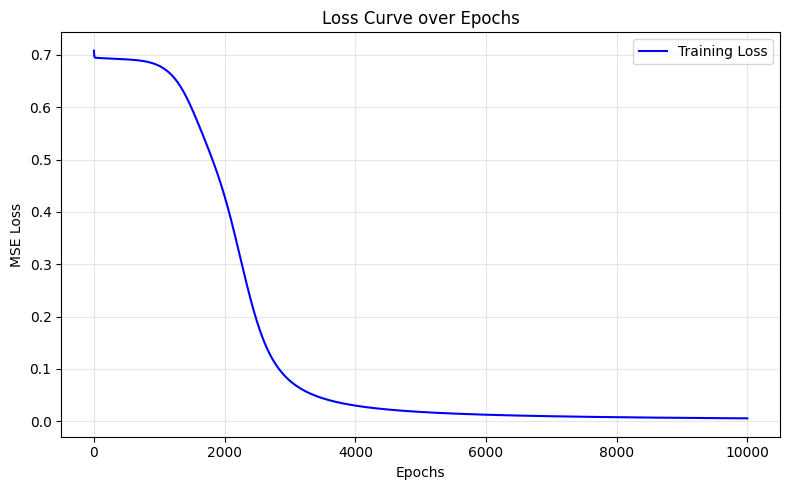

In [ ]:
print("\n" + "=" * 70)
print(" Statistics")
print("=" * 70)


print(f"\n Final Loss:")
print(f"   Mean: {df['final_loss'].mean():.6f}")
print(f"   Std:  {df['final_loss'].std():.6f}")
print(f"   Min:  {df['final_loss'].min():.6f}")
print(f"   Max:  {df['final_loss'].max():.6f}")
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
plt.plot(model.history_, label="Training Loss", color='blue')
plt.title("Loss Curve over Epochs")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()